In [31]:
import heapq
import networkx as nx
import matplotlib.pyplot as plt

In [32]:
# Ví dụ đồ thị vô hướng (đường 2 chiều) gồm 4 khu vực
graph = {
    "Q1": {"Q3": 10, "BinhThanh": 15, "Q4": 8},
    "Q3": {"Q1": 10, "PhuNhuan": 12},
    "BinhThanh": {"Q1": 15, "PhuNhuan": 10},
    "PhuNhuan": {"Q3": 12, "BinhThanh": 10},
    "Q4": {"Q1": 8}
}

# 1. Xem tất cả các đường đi xuất phát từ Q1:
print("Từ Q1 đi được tới:", graph["Q1"])

# 2. Lấy thời gian đi từ Q1 sang BinhThanh:
print("Q1 -> BinhThanh mất:", graph["Q1"]["BinhThanh"], "phút")

# 3. Duyệt qua các nút hàng xóm của Q1:
for hang_xom, thoi_gian in graph["Q1"].items():
    print(f"Đi từ Q1 tới {hang_xom} hết {thoi_gian} phút")

Từ Q1 đi được tới: {'Q3': 10, 'BinhThanh': 15, 'Q4': 8}
Q1 -> BinhThanh mất: 15 phút
Đi từ Q1 tới Q3 hết 10 phút
Đi từ Q1 tới BinhThanh hết 15 phút
Đi từ Q1 tới Q4 hết 8 phút


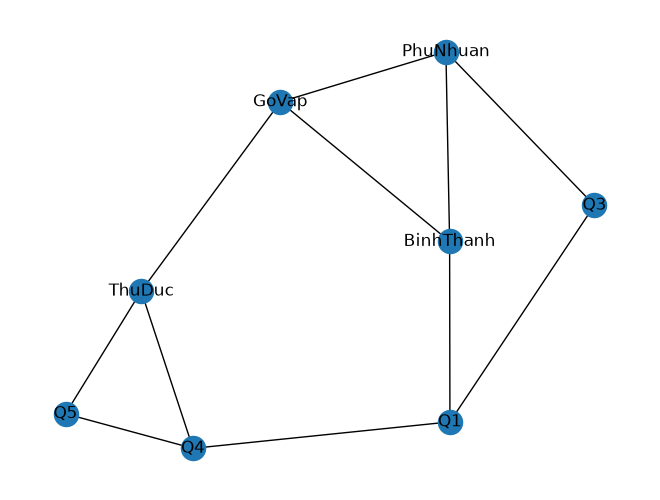

số nút là: 8, sô cạnh là: 11.0


In [33]:


hcm_graph={
    "Q1": {"Q3": 10, "BinhThanh": 15, "Q4": 8},
    "Q3": {"Q1": 10, "PhuNhuan": 12},
    "BinhThanh": {"Q1": 15, "PhuNhuan": 10, "GoVap": 5},
    "PhuNhuan": {"Q3": 12, "BinhThanh": 10, "GoVap": 18 },
    "Q4": {"Q1": 8, "Q5": 20,"ThuDuc": 25},
    "GoVap": {"BinhThanh": 5, "PhuNhuan": 18,"ThuDuc": 15},
    "ThuDuc": {"Q4": 25, "GoVap": 15, "Q5": 30},
    "Q5": {"Q4": 20, "ThuDuc": 30}
}
def kiem_tra_doi_xung(graph):
    for node, neighbors in graph.items():
        for neighbor, weight in neighbors.items():
            if node not in graph[neighbor] or graph[neighbor][node] != weight:
                return False
    return True
canh = 0
nut = len(hcm_graph)
for ten,hang_xom in hcm_graph.items():
    canh +=len(hcm_graph[ten])
    
G = nx.Graph()
for node,neighbors in hcm_graph.items():
    for neighbor, weight in neighbors.items():
        G.add_edge(node,neighbor,weight=weight)

    
nx.draw(G, with_labels=True)
plt.show()

print(f"số nút là: {nut}, sô cạnh là: {canh/2}")



In [34]:


def dijkstra(graph, start):
    # 1. Khởi tạo khoảng cách tới mọi nút là vô cực
    distances = {node: float('inf') for node in graph}
    distances[start] = 0
    
    # 2. Hàng đợi ưu tiên lưu tuple (khoảng_cách, tên_nút)
    pq = [(0, start)]
    
    while pq:
        # Bốc nút có khoảng cách nhỏ nhất hiện tại
        current_dist, current_node = heapq.heappop(pq)
        
        # Mẹo tối ưu: Nếu khoảng cách lấy ra lớn hơn kỷ lục đã lưu thì bỏ qua
        if current_dist > distances[current_node]:
            continue
            
        # Duyệt các nút hàng xóm
        for neighbor, weight in graph[current_node].items():
            new_dist = current_dist + weight
            
            # Nếu tìm thấy đường đi ngắn hơn -> Cập nhật và đẩy vào heap
            if new_dist < distances[neighbor]:
                distances[neighbor] = new_dist
                heapq.heappush(pq, (new_dist, neighbor))
                
    return distances

In [41]:
print(dijkstra(hcm_graph,"Q1"))

nx_lengths = nx.single_source_dijkstra_path_length(G, "Q1", weight="weight")
print(nx_lengths)

{'Q1': 0, 'Q3': 10, 'BinhThanh': 15, 'PhuNhuan': 22, 'Q4': 8, 'GoVap': 20, 'ThuDuc': 33, 'Q5': 28}
{'Q1': 0, 'Q4': 8, 'Q3': 10, 'BinhThanh': 15, 'GoVap': 20, 'PhuNhuan': 22, 'Q5': 28, 'ThuDuc': 33}


In [62]:
# Giả sử vị trí xuất phát của 4 người trên đồ thị
friends_nodes = {
    "An": "Q1",
    "Bình": "GoVap",
    "Chi": "Q5",
    "Phi": "ThuDuc"
}

# Bước 1: Chạy Dijkstra từ vị trí của từng người (chỉ mất 4 lần chạy)
all_distances = {}
for ten, start_node in friends_nodes.items():
    all_distances[ten] = dijkstra(hcm_graph, start_node)

best_sum_node = None
min_sum = float('inf')

best_max_node = None
min_max = float('inf')

for node in hcm_graph:
    times_to_node = [all_distances[ten][node] for ten in friends_nodes]
    f_sum = sum(times_to_node)
    f_max = max(times_to_node)
    print(f"Nút {node:<10} | Chi tiết: {str(times_to_node):<18} | Tổng (F_sum): {f_sum:>3} phút | Lâu nhất (F_max): {f_max:>2} phút")
    if f_sum < min_sum:
        min_sum = f_sum
        best_sum_node = node
        
    # Cập nhật kỷ lục cho tiêu chí Công bằng nhất (F_max)
    if f_max < min_max:
        min_max = f_max
        best_max_node = node
print("-" * 85)
print(f"🏆 Tối ưu theo TỔNG THỜI GIAN (F_sum): {best_sum_node} (Tổng {min_sum} phút)")
print(f"⚖️ Tối ưu theo CÔNG BẰNG NHẤT (F_max): {best_max_node} (Người lâu nhất mất {min_max} phút)")


Nút Q1         | Chi tiết: [0, 20, 28, 33]    | Tổng (F_sum):  81 phút | Lâu nhất (F_max): 33 phút
Nút Q3         | Chi tiết: [10, 27, 38, 42]   | Tổng (F_sum): 117 phút | Lâu nhất (F_max): 42 phút
Nút BinhThanh  | Chi tiết: [15, 5, 43, 20]    | Tổng (F_sum):  83 phút | Lâu nhất (F_max): 43 phút
Nút PhuNhuan   | Chi tiết: [22, 15, 50, 30]   | Tổng (F_sum): 117 phút | Lâu nhất (F_max): 50 phút
Nút Q4         | Chi tiết: [8, 28, 20, 25]    | Tổng (F_sum):  81 phút | Lâu nhất (F_max): 28 phút
Nút GoVap      | Chi tiết: [20, 0, 45, 15]    | Tổng (F_sum):  80 phút | Lâu nhất (F_max): 45 phút
Nút ThuDuc     | Chi tiết: [33, 15, 30, 0]    | Tổng (F_sum):  78 phút | Lâu nhất (F_max): 33 phút
Nút Q5         | Chi tiết: [28, 45, 0, 30]    | Tổng (F_sum): 103 phút | Lâu nhất (F_max): 45 phút
-------------------------------------------------------------------------------------
🏆 Tối ưu theo TỔNG THỜI GIAN (F_sum): ThuDuc (Tổng 78 phút)
⚖️ Tối ưu theo CÔNG BẰNG NHẤT (F_max): Q4 (Người lâu nhất mất 